# Influential instances

A court uses a model that predicts the risk that a defendant is rearrested within two years.
The question here is about the **training data**: is there a single training row without
which the model would be a different model?

The test is simple. Train a model `f` on all rows and a model `g` without one row. If the two
models differ much, the row is influential. The first part of this notebook draws that for
models with one feature, the age. The second part does the test for each row of a data set
with known errors, for a model with all features.

In [1]:
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from recidivism_data import FEATURES, TARGET, load, load_xy, onehot
from recidivism_data.theme import BLUE, INK, INK2, MUTED, ORANGE, use_theme
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import log_loss

warnings.filterwarnings("ignore")
use_theme()

X_train, y_train = load_xy("train")
A = X_train[["age"]].astype(float)
rate = y_train.groupby(X_train["age"]).agg(["mean", "size"])

## One added person changes boosted trees

We add one synthetic person to the 7 253 training rows: **85 years old, rearrested**. The
oldest real person is 75. The boosted trees here may put a single person into a leaf
(`min_samples_leaf=1`).

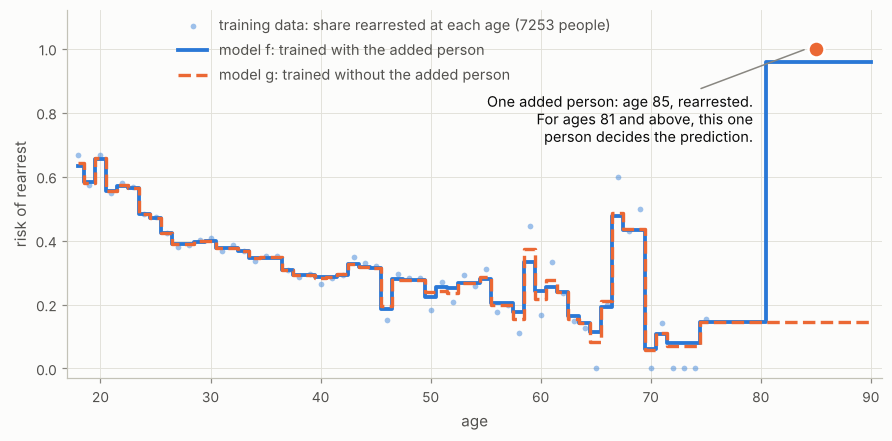

risk at age 85: 0.15 without the person, 0.96 with the person
largest difference below age 76: 0.04


In [2]:
NEW_AGE, NEW_LABEL = 85.0, 1


def train(
    A: pd.DataFrame, y: pd.Series, min_samples_leaf: int = 1
) -> HistGradientBoostingClassifier:
    model = HistGradientBoostingClassifier(
        max_iter=150,
        learning_rate=0.05,
        max_depth=3,
        min_samples_leaf=min_samples_leaf,
        random_state=0,
    )
    return model.fit(A, y)


def risk(model, ages) -> np.ndarray:
    return model.predict_proba(pd.DataFrame({"age": np.asarray(ages, float)}))[:, 1]


A_plus = pd.concat([A, pd.DataFrame({"age": [NEW_AGE]})], ignore_index=True)
y_plus = pd.concat([y_train, pd.Series([NEW_LABEL])], ignore_index=True)
g = train(A, y_train)  # without the added person
f = train(A_plus, y_plus)  # with the added person

ages = np.arange(18, 91.0)
with_person, without = risk(f, ages), risk(g, ages)
changed = ages[np.abs(with_person - without) > 0.1]

fig, ax = plt.subplots(figsize=(8, 3.9))
label = f"training data: share rearrested at each age ({len(A)} people)"
ax.scatter(rate.index, rate["mean"], s=14, color=BLUE, alpha=0.45, linewidth=0, label=label)
ax.step(
    ages,
    with_person,
    where="mid",
    color=BLUE,
    linewidth=2.5,
    label="model f: trained with the added person",
)
ax.step(
    ages,
    without,
    where="mid",
    color=ORANGE,
    linewidth=2.2,
    linestyle="--",
    label="model g: trained without the added person",
)
ax.scatter([NEW_AGE], [NEW_LABEL], s=110, color=ORANGE, edgecolor="white", linewidth=1.6, zorder=5)
text = f"One added person: age 85, rearrested.\nFor ages {changed.min():.0f} and above, this one\nperson decides the prediction."
ax.annotate(
    text,
    (NEW_AGE - 0.8, 1.0),
    xytext=(79.3, 0.78),
    ha="right",
    va="center",
    color=INK,
    fontsize=9.5,
    arrowprops={"arrowstyle": "-", "color": MUTED},
)
ax.set(xlabel="age", ylabel="risk of rearrest", xlim=(17, 91), ylim=(-0.03, 1.12))
ax.legend(loc="upper left", labelcolor=INK2, fontsize=9.5, bbox_to_anchor=(0.12, 1.02))
plt.show()

print(
    f"risk at age 85: {risk(g, [85])[0]:.2f} without the person, {risk(f, [85])[0]:.2f} with the person"
)
print(f"largest difference below age 76: {np.abs(with_person - without)[ages < 76].max():.2f}")

A person is influential when the person is **alone in a region** of the data. Two checks:

In [3]:
inside = pd.concat([A, pd.DataFrame({"age": [72.0]})], ignore_index=True)
f_inside = train(inside, y_plus)
print(
    f"an added person of age 72 (inside the data): largest change {np.abs(risk(f_inside, ages) - without).max():.2f}"
)

g_regular, f_regular = train(A, y_train, 40), train(A_plus, y_plus, 40)
print("at least 40 people in a leaf (the setting of the other projects):", end=" ")
print(
    f"risk at age 85 is {risk(g_regular, [85])[0]:.2f} without and {risk(f_regular, [85])[0]:.2f} with the person"
)

an added person of age 72 (inside the data): largest change 0.09


at least 40 people in a leaf (the setting of the other projects): risk at age 85 is 0.13 without and 0.15 with the person


Inside the range of the data, the model averages the person with the neighbors.
Regularization does the same for the person outside the range.

## One wrong record changes a linear model

A linear model has no regions: each point pulls on the whole line, and a point far from the
others pulls most. Here the training data is the share rearrested at each age, plus **one
record with a data-entry error** from the dirty data set: a 25-year-old entered as 125. For
each point we train the line again without it (leave one out); the size of a dot is its
influence.

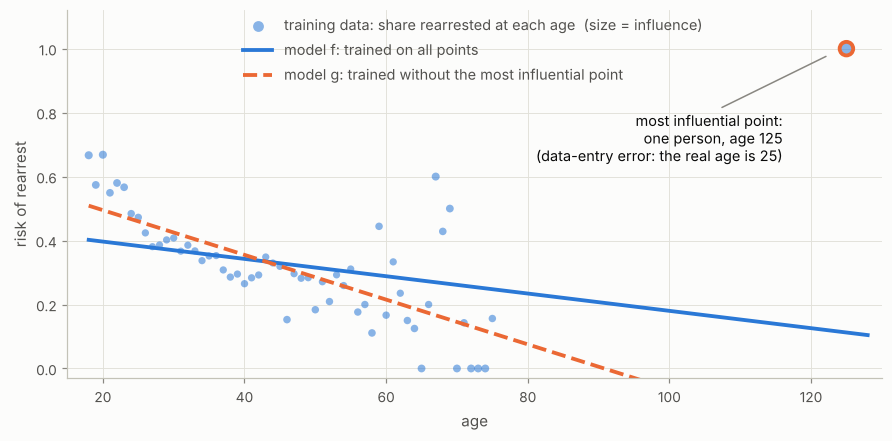

with the record:    risk = 0.45 -0.0027 · age
without the record: risk = 0.63 -0.0070 · age
influence of the record: 9 times that of the second point


In [4]:
log = load("error_log")
dirty = load("defendants_dirty").set_index("id")
wrong = log[(log["kind"] == "age_plus_100") & log["dirty_value"].between(120, 126)].iloc[0]
record = dirty.loc[wrong["id"]]

x = np.append(rate.index.to_numpy(float), float(record["age"]))
y = np.append(rate["mean"].to_numpy(), float(record["rearrested"]))


def line(keep) -> np.ndarray:
    return np.polyfit(x[keep], y[keep], 1)  # slope, intercept


everything = line(np.ones(len(x), bool))
check = np.linspace(18, 75, 58)
influence = np.zeros(len(x))
for i in range(len(x)):  # leave one out
    without_i = line(np.arange(len(x)) != i)
    influence[i] = np.abs(np.polyval(without_i, check) - np.polyval(everything, check)).mean()
top = int(np.argmax(influence))
without_top = line(np.arange(len(x)) != top)

grid = np.array([18.0, 128.0])
fig, ax = plt.subplots(figsize=(8, 3.9))
ax.scatter(
    x,
    y,
    s=22 + 900 * influence,
    color=BLUE,
    alpha=0.55,
    linewidth=0,
    label="training data: share rearrested at each age  (size = influence)",
)
ax.plot(
    grid,
    np.polyval(everything, grid),
    color=BLUE,
    linewidth=2.5,
    label="model f: trained on all points",
)
ax.plot(
    grid,
    np.polyval(without_top, grid),
    color=ORANGE,
    linewidth=2.5,
    linestyle="--",
    label="model g: trained without the most influential point",
)
ax.scatter(
    [x[top]],
    [y[top]],
    s=22 + 900 * influence[top],
    facecolor="none",
    edgecolor=ORANGE,
    linewidth=2.5,
    zorder=4,
)
text = f"most influential point:\none person, age {x[top]:.0f}\n(data-entry error: the real age is {wrong['clean_value']})"
ax.annotate(
    text,
    (x[top] - 2.5, y[top] - 0.02),
    xytext=(x[top] - 9, 0.72),
    ha="right",
    va="center",
    color=INK,
    fontsize=9.5,
    arrowprops={"arrowstyle": "-", "color": MUTED},
)
ax.set(xlabel="age", ylabel="risk of rearrest", xlim=(15, 130), ylim=(-0.03, 1.12))
ax.legend(loc="upper left", labelcolor=INK2, fontsize=9.5, bbox_to_anchor=(0.2, 1.02))
plt.show()

print(f"with the record:    risk = {everything[1]:.2f} {everything[0]:+.4f} · age")
print(f"without the record: risk = {without_top[1]:.2f} {without_top[0]:+.4f} · age")
print(
    f"influence of the record: {influence[top] / np.sort(influence)[-2]:.0f} times that of the second point"
)

One wrong record makes the effect of age less than half as strong.

## Find the influential rows of a data set with errors

Now a logistic regression with all features, trained on 1 500 rows of the dirty training
data: 1 440 correct rows and the 60 rows with an injected error (`priors_count + 90`,
`age + 100`, or a flipped label). The log of the errors is the ground truth: we can count how
many of the most influential rows are errors.

In [5]:
C = 1.0

dirty = load("defendants_dirty").query("split == 'train'")
log = load("error_log")
kind = log.sort_values("column").groupby("id")["kind"].first()  # the value error, if there is one
clean_rows = dirty[~dirty["id"].isin(kind.index)].sample(1440, random_state=0)
sample = pd.concat([dirty[dirty["id"].isin(kind.index)], clean_rows]).sample(frac=1, random_state=0)
sample = sample.reset_index(drop=True)
is_error = sample["id"].isin(kind.index).to_numpy()
clean = load().set_index("id").loc[sample["id"]].reset_index()

A = onehot(sample[FEATURES]).to_numpy()
y = sample[TARGET].to_numpy()
X_valid, y_valid = load_xy("valid")
A_valid = onehot(X_valid).to_numpy()
names = list(onehot(sample[FEATURES]).columns)


def fit(A, y, start=None):
    model = LogisticRegression(C=C, max_iter=3000, tol=1e-8, warm_start=start is not None)
    if start is not None:
        model.coef_, model.intercept_ = start.coef_.copy(), start.intercept_.copy()
    return model.fit(A, y)


def theta(model) -> np.ndarray:
    return np.append(model.coef_[0], model.intercept_[0])


def quality(model) -> tuple[float, float]:
    return model.score(A_valid, y_valid), log_loss(y_valid, model.predict_proba(A_valid)[:, 1])

### A model on 1500 training rows; 60 of them have a data-entry error

In [6]:
f = fit(A, y)
f_clean = fit(onehot(clean[FEATURES]).to_numpy(), clean[TARGET].to_numpy())
for label, model in [("with the errors", f), ("without errors", f_clean)]:
    accuracy, loss = quality(model)
    weights = dict(zip(names, model.coef_[0]))
    print(f"   {label}: accuracy {accuracy:.3f}, log loss {loss:.4f},", end=" ")
    print(f"weight of priors_count {weights['priors_count']:+.3f}, of age {weights['age']:+.3f}")
print("   Is the model skewed by a few rows? Which ones?")

   with the errors: accuracy 0.647, log loss 0.6242, weight of priors_count -0.022, of age +0.015
   without errors: accuracy 0.681, log loss 0.6062, weight of priors_count +0.123, of age -0.037
   Is the model skewed by a few rows? Which ones?


### Leave one out: train the model again without row i, for each i

This trains 1 500 models and takes about 40 seconds.

In [7]:
start = time.perf_counter()
base_loss = quality(f)[1]
change_theta = np.zeros((len(y), len(theta(f))))
change_loss = np.zeros(len(y))
for i in range(len(y)):
    keep = np.arange(len(y)) != i
    g = fit(A[keep], y[keep], start=f)
    change_theta[i] = theta(g) - theta(f)
    change_loss[i] = quality(g)[1] - base_loss
seconds_loo = time.perf_counter() - start
scale = np.append(A.std(axis=0), 1.0)
influence = np.linalg.norm(change_theta * scale, axis=1)  # change of the parameters
print(f"   {len(y)} models trained in {seconds_loo:.0f} s")


def report(score: np.ndarray, label: str) -> None:
    order = np.argsort(-score)
    hits = {k: int(is_error[order[:k]].sum()) for k in (20, 60)}
    print(f"   {label}: {hits[20]} of the top 20 and {hits[60]} of the top 60 are injected errors")
    kinds = kind.reindex(sample.loc[order[:60], "id"]).value_counts().to_dict()
    print(f"      kinds in the top 60: {kinds}")

   1500 models trained in 36 s


### The most influential rows, compared with the log of the injected errors

In [8]:
report(influence, "largest change of the parameters")
report(-change_loss, "largest improvement on validation data when removed")
top = np.argsort(-influence)[:5]
columns = ["id", "age", "priors_count", TARGET]
print("   the five rows with the largest change of the parameters (none is an error):")
print(
    "   " + sample.loc[top, columns].assign(error=is_error[top]).to_string().replace("\n", "\n   ")
)
found = set(np.argsort(change_loss)[:60])
by_kind = pd.Series(kind.reindex(sample["id"]).to_numpy())[is_error]
share = by_kind.groupby(by_kind).apply(lambda s: np.mean([i in found for i in s.index]))
print(
    "   share of each kind of error in the top 60 (validation): "
    + ", ".join(f"{k} {v:.0%}" for k, v in share.items())
)

   largest change of the parameters: 2 of the top 20 and 7 of the top 60 are injected errors
      kinds in the top 60: {'label_flip': 4, 'age_plus_100': 3}
   largest improvement on validation data when removed: 10 of the top 20 and 16 of the top 60 are injected errors
      kinds in the top 60: {'age_plus_100': 14, 'label_flip': 2}
   the five rows with the largest change of the parameters (none is an error):
          id  age  priors_count  rearrested  error
   972   766   75             1           1  False
   663  7810   33            18           0  False
   852  1893   53             1           1  False
   326  8505   60             2           1  False
   294  5240   25             2           1  False
   share of each kind of error in the top 60 (validation): age_plus_100 70%, label_flip 10%, priors_plus_90 0%


### Without retraining: influence functions (one Hessian, one gradient per row)

For a logistic regression, the change of the parameters when one row is removed can be
approximated from the Hessian matrix of the loss and the gradient of that row.

In [9]:
start = time.perf_counter()
A1 = np.column_stack([A, np.ones(len(y))])
p = f.predict_proba(A)[:, 1]
gradients = A1 * (p - y)[:, None]
regularization = np.diag(np.append(np.ones(A.shape[1]), 0.0)) / C
hessian = (A1 * (p * (1 - p))[:, None]).T @ A1 + regularization
approx_theta = np.linalg.solve(hessian, gradients.T).T  # removing row i changes theta by this
seconds_if = time.perf_counter() - start
approx = np.linalg.norm(approx_theta * scale, axis=1)
print(f"   computed in {seconds_if * 1000:.0f} ms ({seconds_loo / seconds_if:.0f} times faster)")
print(f"   correlation with the leave-one-out result: {np.corrcoef(approx, influence)[0, 1]:.3f}")
report(approx, "largest approximate change of the parameters")

   computed in 1 ms (34554 times faster)
   correlation with the leave-one-out result: 1.000
   largest approximate change of the parameters: 2 of the top 20 and 7 of the top 60 are injected errors
      kinds in the top 60: {'label_flip': 4, 'age_plus_100': 3}


### Use: remove the rows whose removal helps most on validation data

In [10]:
order = np.argsort(change_loss)
for k in [0, 20, 60]:
    keep = np.ones(len(y), bool)
    keep[order[:k]] = False
    accuracy, loss = quality(fit(A[keep], y[keep]))
    print(f"   without the top {k:2d}: accuracy {accuracy:.3f}, log loss {loss:.4f}")
accuracy, loss = quality(f_clean)
print(f"   all errors corrected: accuracy {accuracy:.3f}, log loss {loss:.4f}")

   without the top  0: accuracy 0.647, log loss 0.6242
   without the top 20: accuracy 0.657, log loss 0.6186
   without the top 60: accuracy 0.668, log loss 0.6156
   all errors corrected: accuracy 0.681, log loss 0.6062


### Limit: one row at a time does not show the effect of a group

In [11]:
priors = names.index("priors_count")
group = np.flatnonzero(kind.reindex(sample["id"]).to_numpy() == "priors_plus_90")
single = change_theta[group, priors]
together = (
    fit(np.delete(A, group, axis=0), np.delete(y, group)).coef_[0][priors] - f.coef_[0][priors]
)
print(f"   weight of priors_count: {f.coef_[0][priors]:+.3f}")
print(
    f"   remove one of the {len(group)} rows with priors + 90: at most {np.abs(single).max():+.3f}"
)
print(f"   sum of the {len(group)} single effects: {single.sum():+.3f}")
print(f"   remove all {len(group)} together: {together:+.3f}")

   weight of priors_count: -0.022
   remove one of the 20 rows with priors + 90: at most +0.001
   sum of the 20 single effects: +0.011
   remove all 20 together: +0.097
